<a href="https://colab.research.google.com/github/AzraNA24/Deforestration-Drivers-Classification/blob/main/Data_ForestFire.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import Earth Engine


In [2]:
import ee
ee.Authenticate()
ee.Initialize(project='deforestation-drivers-508922')

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR = '/content/drive/MyDrive/skripsi_data'
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(f'{DATA_DIR}/patches', exist_ok=True)
os.makedirs(f'{DATA_DIR}/rasters', exist_ok=True)
os.makedirs(f'{DATA_DIR}/tables',  exist_ok=True)
os.makedirs(f'{DATA_DIR}/maps',    exist_ok=True)
os.makedirs(f'{DATA_DIR}/anim',    exist_ok=True)
os.makedirs(f'{DATA_DIR}/forest_fire',    exist_ok=True)
print("Struktur folder:")
for root, dirs, files in os.walk(DATA_DIR):
    level = root.replace(DATA_DIR, '').count(os.sep)
    print('  '*level + os.path.basename(root) + '/')

Mounted at /content/drive
Struktur folder:
skripsi_data/
  patches/
  rasters/
  tables/
  maps/
  anim/
  forest_fire/


## Ambil Area

In [4]:
provinces = ee.FeatureCollection('FAO/GAUL/2015/level1')
kalteng = provinces.filter(ee.Filter.eq('ADM1_NAME', 'Kalimantan Tengah'))
aoi = kalteng.geometry()

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level1! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level1

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level1

  warnings.warn(warning, category=DeprecationWarning)


## Mengambil Data Forest Fire Loss

In [5]:
def load_asset(asset_id):
    t = ee.data.getAsset(asset_id)['type']
    if t == 'IMAGE_COLLECTION':
        return ee.ImageCollection(asset_id).mosaic()
    return ee.Image(asset_id)

fire_cert = load_asset('users/sashatyu/2001-2025_fire_forest_loss')
fire_year = load_asset('users/sashatyu/2001-2025_fire_forest_loss_annual')

print(fire_cert.bandNames().getInfo(), fire_year.bandNames().getInfo())

['b1'] ['b1']


### Mask Fire ke Window Studi

In [6]:
yr = fire_year.select(0)
fire_label = yr.gte(20).And(yr.lte(25)).selfMask().clip(aoi)

area = (ee.Image.pixelArea().divide(10000)
        .addBands(yr.updateMask(fire_label))
        .reduceRegion(
            reducer=ee.Reducer.sum().group(groupField=1, groupName='lossyear'),
            geometry=aoi, scale=30, maxPixels=1e13, tileScale=4))
print(area.getInfo())

{'groups': [{'lossyear': 20, 'sum': 12025.617737943734}, {'lossyear': 21, 'sum': 2079.4480322750046}, {'lossyear': 22, 'sum': 2516.5610762095034}, {'lossyear': 23, 'sum': 21620.297241574233}, {'lossyear': 24, 'sum': 8043.458398702871}, {'lossyear': 25, 'sum': 5752.649586151877}]}


### Mengambil titik Sampel Berlabel

In [7]:
samples = (yr.updateMask(fire_label).rename('lossyear')
    .stratifiedSample(
        numPoints=0, classBand='lossyear', region=aoi, scale=30,
        classValues=[20, 21, 22, 23, 24, 25], classPoints=[250, 250, 250, 250, 250, 250],
        seed=42, geometries=True, tileScale=4))

def add_meta(f):
    c = f.geometry().coordinates()
    return f.set({'lon': c.get(0), 'lat': c.get(1),
                  'label': 'fire', 'source': 'Tyukavina2022'})

samples = samples.map(add_meta)

task = ee.batch.Export.table.toDrive(
    collection=samples, description='labels_fire',
    folder='skripsi_data', fileNamePrefix='labels_fire', fileFormat='CSV',
    selectors=['lon', 'lat', 'lossyear', 'label', 'source'])
task.start()

In [8]:
import numpy as np, pandas as pd
from sklearn.neighbors import BallTree

df = pd.read_csv(f'{DATA_DIR}/labels_fire.csv')
MIN_DIST_M = 1280

def thin_points(df, min_dist_m, seed=42):
    df = df.sample(frac=1, random_state=seed).reset_index(drop=True)
    rad = np.radians(df[['lat', 'lon']].values)
    tree = BallTree(rad, metric='haversine')
    neighbors = tree.query_radius(rad, r=min_dist_m / 6371000.0)
    keep = np.ones(len(df), dtype=bool)
    for i in range(len(df)):
        if keep[i]:
            for j in neighbors[i]:
                if j != i:
                    keep[j] = False
    return df[keep]

thinned = thin_points(df, MIN_DIST_M)
print(len(df), '->', len(thinned))
print(thinned['lossyear'].value_counts().sort_index())

1500 -> 1065
lossyear
20    177
21    173
22    182
23    181
24    169
25    183
Name: count, dtype: int64


### Cross Check Area dengan Hansen

In [9]:
hansen = ee.Image('UMD/hansen/global_forest_change_2025_v1_13')
agree = hansen.select('lossyear').eq(yr).updateMask(fire_label)
print(agree.reduceRegion(ee.Reducer.mean(), aoi, 30,
                         maxPixels=1e13, tileScale=4).getInfo())

{'lossyear': 1}


Ini nunjukin kalau datanya bener (akurat)

## Mendapatkan Citra

### Siapkan Titik dan Citra Dasar

In [12]:
def mask_clouds(image):
    scl = image.select('SCL')
    # SCL class 3 = cloud shadow, 8-10 = cloud (medium/high prob + cirrus), 11 = snow
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return image.updateMask(mask)

def add_ndvi(image):
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return image.addBands(ndvi)

In [13]:
import pandas as pd, ee

df = pd.read_csv(f'{DATA_DIR}/labels_fire.csv')   # atau `thinned` kalau sudah di-thinning
df['patch_id'] = [f"fire_{int(r.lossyear)}_{i:05d}" for i, r in enumerate(df.itertuples())]

S2_BANDS = ['B4', 'B8', 'B11', 'NDVI']   # bisa ditambah B2, B3, B12

col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
       .filterBounds(aoi)
       .filterDate('2019-01-01', '2026-10-01')
       .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
      .map(add_ndvi))

def yearly_median(year):
    return (col.filterDate(f'{year}-01-01', f'{year}-12-31')
               .median().select(S2_BANDS))

### Build gambar sebelum & Sesudah Titik

In [14]:
def build_image(lossyear):
    year = 2000 + int(lossyear)
    before = yearly_median(year - 1).rename([f'{b}_before' for b in S2_BANDS])
    after  = yearly_median(year + 1).rename([f'{b}_after'  for b in S2_BANDS])
    return before.addBands(after).toFloat().unmask(0)   # 8 channel

### Download Patch

In [15]:
import requests, time
from concurrent.futures import ThreadPoolExecutor

HALF = 640
os.makedirs(f'{DATA_DIR}/patches', exist_ok=True)

def download_patch(row, retries=3):
    out = f"{DATA_DIR}/patches/{row['patch_id']}.tif"
    if os.path.exists(out):
        return 'skip'
    region = ee.Geometry.Point([row['lon'], row['lat']]).buffer(HALF).bounds()
    img = build_image(row['lossyear'])
    for k in range(retries):
        try:
            url = img.getDownloadURL({'region': region, 'scale': 10,
                                      'format': 'GEO_TIFF'})
            r = requests.get(url, timeout=120)
            r.raise_for_status()
            with open(out, 'wb') as f:
                f.write(r.content)
            return 'ok'
        except Exception as e:
            time.sleep(2 * (k + 1))
    return f"gagal: {row['patch_id']}"

rows = df.to_dict('records')
with ThreadPoolExecutor(max_workers=8) as ex:
    results = list(ex.map(download_patch, rows))

print(pd.Series(results).str[:5].value_counts())

ok    1500
Name: count, dtype: int64


In [16]:
import numpy as np, rasterio, torch
from torch.utils.data import Dataset

CLASSES = {'fire': 0, 'plantation': 1, 'agriculture': 2, 'grassland': 3}
SIZE = 64

class PatchDataset(Dataset):
    def __init__(self, df, mean, std, augment=False):
        self.df, self.mean, self.std, self.augment = df.reset_index(drop=True), mean, std, augment

    def __len__(self): return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        with rasterio.open(f"{DATA_DIR}/patches/{row['patch_id']}.tif") as src:
            x = src.read().astype('float32')
        _, H, W = x.shape
        t, l = (H - SIZE) // 2, (W - SIZE) // 2
        x = x[:, t:t+SIZE, l:l+SIZE]
        x = (x - self.mean[:, None, None]) / self.std[:, None, None]   # normalisasi per channel
        if self.augment:
            if np.random.rand() < 0.5: x = x[:, :, ::-1]
            if np.random.rand() < 0.5: x = x[:, ::-1, :]
            x = np.rot90(x, np.random.randint(4), axes=(1, 2))
        return torch.from_numpy(x.copy()), CLASSES[row['label']]

Outputnya akan menjadi sesuatu seperti ini


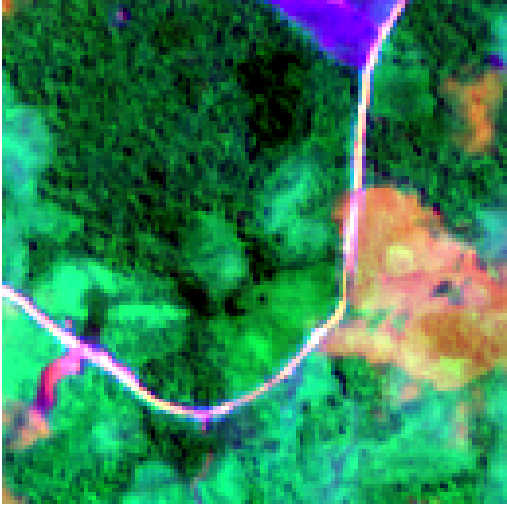

Satu file Tiff, mengandung 8 band;
1-4 yang berisis B4, B8, B11, NDVI sebelum loss (komposit tahun loss − 1)
dan 5-8 #yang berisi B4, B8, B11, NDVI sesudah loss (komposit tahun loss + 1)

The reason it looks kinda freaky, it's because QGIS secara default menampilkan band 1, 2, 3 sebagai Red, Green, Blue. Jadi yang terlihat adalah gambar sebelum loss, dengan komposisi warna palsu: R = Red (B4), G = NIR (B8), B = SWIR (B11). Itu sebabnya warnanya tidak seperti foto biasa:

### True Color Testing

In [17]:
import requests, io
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def get_rgb_thumb(region, year, dim=512):
    comp = (col.filterDate(f'{year}-01-01', f'{year}-12-31')
               .median().clip(region))
    vis = comp.visualize(bands=['B4', 'B3', 'B2'], min=0, max=3000, gamma=1.2)
    url = vis.getThumbURL({'region': region, 'dimensions': dim, 'format': 'png'})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=120).content)))

def before_after(row, half=1000, dim=512):
    """half=1000 m -> kotak 2 km x 2 km, lebih luas dari patch model agar konteks terlihat"""
    year = 2000 + int(row['lossyear'])
    region = ee.Geometry.Point([row['lon'], row['lat']]).buffer(half).bounds()
    return get_rgb_thumb(region, year - 1), get_rgb_thumb(region, year + 1), year

Ambil kandidat dengan NDVI yang tajam dari 40-an data

In [18]:
def ndvi_drop(row, radius=100):
    pt = ee.Geometry.Point([row['lon'], row['lat']]).buffer(radius)
    year = 2000 + int(row['lossyear'])
    b = yearly_median(year - 1).select('NDVI')
    a = yearly_median(year + 1).select('NDVI')
    v = a.subtract(b).reduceRegion(ee.Reducer.mean(), pt, 10).get('NDVI').getInfo()
    return v

cand = df.sample(40, random_state=1).copy()
cand['dNDVI'] = [ndvi_drop(r) for r in cand.to_dict('records')]
best = cand.sort_values('dNDVI').head(6)    # penurunan paling tajam

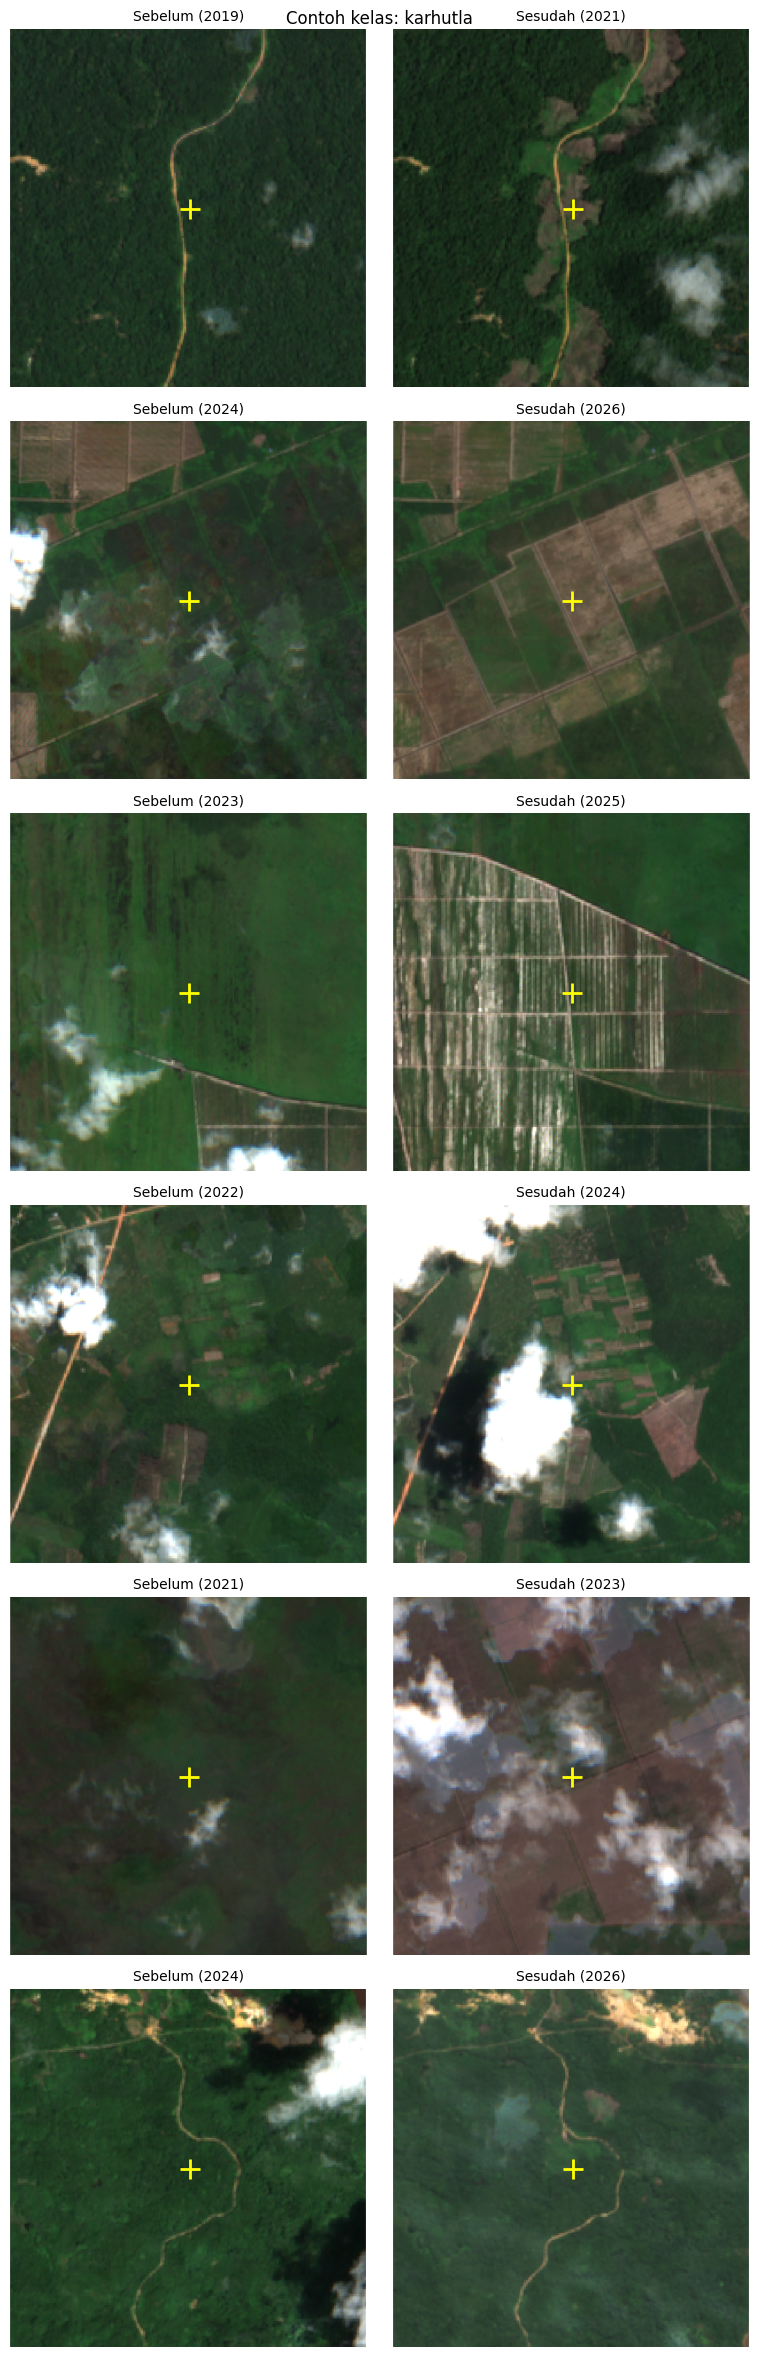

In [19]:
def plot_examples(rows, title, out_path):
    n = len(rows)
    fig, axes = plt.subplots(n, 2, figsize=(8, 4 * n))
    axes = np.atleast_2d(axes)
    for i, row in enumerate(rows.to_dict('records')):
        bef, aft, year = before_after(row)
        for ax, im, t in zip(axes[i], (bef, aft),
                             (f'Sebelum ({year-1})', f'Sesudah ({year+1})')):
            ax.imshow(im); ax.set_title(t, fontsize=10)
            c = im.shape[0] // 2
            ax.plot(c, c, marker='+', color='yellow', markersize=14, mew=2)  # titik label
            ax.axis('off')
        axes[i, 0].set_ylabel(row['label'])
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()

plot_examples(best, 'Contoh kelas: karhutla', f'{DATA_DIR}/maps/contoh_fire.png')

Bukti Api

In [25]:
def fire_evidence(row, radius=500):
    year = 2000 + int(row['lossyear'])
    pt = ee.Geometry.Point([row['lon'], row['lat']]).buffer(radius)

    burned = (ee.ImageCollection('MODIS/061/MCD64A1')
              .filterDate(f'{year}-01-01', f'{year}-12-31')
              .select('BurnDate').max())
    burned_px = burned.gt(0).reduceRegion(ee.Reducer.max(), pt, 500).get('BurnDate')

    hotspots = (ee.ImageCollection('FIRMS')
                .filterDate(f'{year}-01-01', f'{year}-12-31')
                .filterBounds(pt).size())
    return {'burned_modis': burned_px.getInfo(), 'n_hotspot_days': hotspots.getInfo()}

In [24]:
year = 2024

def nbr(img):
    return img.normalizedDifference(['B8', 'B12'])

pre = col.filterDate(
    f'{year}-05-01',
    f'{year}-07-31'
).median()

post = col.filterDate(
    f'{year}-11-01',
    f'{year+1}-01-31'
).median()

dnbr = nbr(pre).subtract(nbr(post))

# def nbr(img): return img.normalizedDifference(['B8', 'B12'])

# pre  = col.filterDate(f'{year}-05-01', f'{year}-07-31').median()
# post = col.filterDate(f'{year+0}-11-01', f'{year+1}-01-31').median()
# dnbr = nbr(pre).subtract(nbr(post))   # nilai tinggi (mis. > 0,27) = indikasi bekas terbakar